In [ ]:

# membuat dataset
data = {
    "Nama": ["Ani", "Budi", "Citra", "Dedi", "Eka", "Fahmi", "Gina"],
    "Usia": [23, 35, 31, 28, 40, 29, 35],
    "Total_Belanja": [250000, 400000, 300000, 275000, 600000, 320000, 400000],
    "Gender": ["F", "M", "F", "M", "F", "M", "F"]
}
df = pd.DataFrame(data)
df

,Nama,Usia,Total_Belanja,Gender
0,Ani,23,250000,F
1,Budi,35,400000,M
2,Citra,31,300000,F
3,Dedi,28,275000,M
4,Eka,40,600000,F
5,Fahmi,29,320000,M
6,Gina,35,400000,F


# Statistik Deskripsi Dasar

*   List item
*   List item



In [ ]:
df.describe()

,Usia,Total_Belanja
count,7.000000,7.000000
mean,31.571429,363571.428571
std,5.593363,119188.725897
min,23.000000,250000.000000
25%,28.500000,287500.000000
50%,31.000000,320000.000000
75%,35.000000,400000.000000
max,40.000000,600000.000000


`df.describe()` memungkinkan kita untuk mendapat ringkasan statistik deskriptif.

- count: jumlah data (non-null)
- mean: rata-rata
- std: standar deviasi
- min: nilai minimum
- 25%: kuartil pertama
- 50%: median (kuartil kedua)
- 75%: kuartil ketiga
- max: nilai maksimum

# Mean, Median, Modus

In [ ]:
print("Rata-rata usia customer:", df['Usia'].mean())
print("Median Usia:", df['Usia'].median())
print("Modus Gender:", df['Gender'].mode()[0])

Rata-rata usia customer: 31.571428571428573
Median Usia: 31.0
Modus Gender: F


In [ ]:
print("Mean Total Belanja:", df['Total_Belanja'].mean())
print("Median Total Belanja:", df['Total_Belanja'].median())

Mean Total Belanja: 363571.4285714286
Median Total Belanja: 320000.0


# Varians dan Standar Deviasi

In [ ]:
print("Varians Belanja:", df['Total_Belanja'].var())
print("Standar Deviasi Belanja:", df['Total_Belanja'].std())


Varians Belanja: 14205952380.95238
Standar Deviasi Belanja: 119188.72589700915


Interpretasi

Dengan:
- Rata-rata belanja: Rp 363.571
- Standar deviasi: Rp 119.189

Berarti sebagian besar data belanja berada dalam rentang:
Rp 244.382 sampai Rp 482.760
(Ini maksudnya dari mean ± 1 standar deviasi ==> 363571 ± 119189)

In [ ]:
print("Varians Usia:", df['Usia'].var())
print("Standar Deviasi Usia:", df['Usia'].std())


Varians Usia: 31.28571428571428
Standar Deviasi Usia: 5.593363414414826


Interpretasi:

Usia-usia dalam dataset tersebar sekitar ±5.6 tahun dari rata-rata usia.

# Expected Value (Rata-rata Pembelian)

Untuk menghitung expected value kita memerlukan data tambahan yaitu probabilitas.

Rumus expected value adalah $E(X) = \sum_{i=1}^{n} x_i P(x_i)$

$P(x_i)$ artinya probabilitas terjadinya $x_i$. Misal, probabilitas terjadinya total belanja Rp 200.000.

Probabilitas ini bisa didapat dari beberapa cara, yaitu:
- Data historis/observasi
  - contoh: dari 100 hari berjualan ..., selama 5 tahun berjualan ... hingga didapat probabilitas bahwa sekitar 20% pelanggan itu berbelanja sebesar 100rb
- Asumsi atau estimasi berdasarkan kategori
  - contoh: ternyata 20% pelanggan biasanya hanya belanja 1 barang (anggaplah barangnya mayoritas seharga Rp100.000), 50% beli 2 barang (Rp200.000), dll.
  - jadi bisa berupa asumsi teoritis atau estimasi berdasarkan hal tertentu
- Model prediktif

Di kasus ini, disediakan probabilitasnya. Anggaplah data ini merupakan hasil dari observasi yang sudah dilakukan sebelumnya.

In [ ]:
# membuat tambahan data untuk mengetahui probabilitas/peluang total belanja.
data_prob = {
    "Total_Belanja": [100000, 200000, 300000],
    "Probabilitas": [0.2, 0.5, 0.3]
}

df_prob = pd.DataFrame(data_prob)
df_prob

,Total_Belanja,Probabilitas
0,100000,0.2
1,200000,0.5
2,300000,0.3


In [ ]:
# menghitung x dikali p (total belanja dikali probabilitasnya)
df_prob['xp'] = df_prob['Total_Belanja'] * df_prob['Probabilitas']
df_prob

,Total_Belanja,Probabilitas,xp
0,100000,0.2,20000.0
1,200000,0.5,100000.0
2,300000,0.3,90000.0


In [ ]:
expected_value = df_prob["xp"].sum()

print("Expected Value (Rp):", expected_value)


Expected Value (Rp): 210000.0


Interpretasi:
* Rata-rata belanja (jangka panjang) yang bisa diperkirakan dari pelanggan adalah Rp210,000
* Bisa jadi dasar promosi seperti “Gratis ongkir untuk pembelanjaan di atas Rp250,000” atau strategi lainnya yang mendorong pelanggan untuk bertransaksi lebih dari rata-rata tersebut.

# Kovariansi dan Korelasi

In [ ]:
print("Kovarians:", df['Usia'].cov(df['Total_Belanja']))
print("Korelasi:", df['Usia'].corr(df['Total_Belanja']))

Kovarians: 613452.3809523808
Korelasi: 0.9201796864428976


- Kovarians > 0 =  positif
- Korelasi 0.92 = sangat kuat. Semakin tinggi usia, semakin tinggi total belanja.

Interpretasi:

Terdapat hubungan linier yang sangat kuat dan positif antara usia dan total belanja. Hal ini menunjukkan bahwa pelanggan yang lebih tua cenderung membelanjakan lebih banyak dibandingkan pelanggan yang lebih muda.

# Distribusi Normal

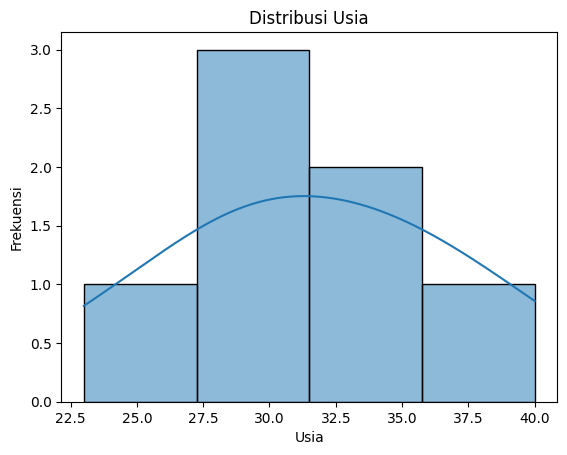

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Distribusi Total Belanja
sns.histplot(df['Usia'], kde=True)
plt.title("Distribusi Usia")
plt.xlabel("Usia")
plt.ylabel("Frekuensi")
plt.show()


Dari histogram di atas, terlihat bahwa distribusi usia merupakan distribusi normal. Bentuknya cukup simetris. Selain itu, dilihat dari deskripsi statistiknya memang menjadi indikasi bahwa distribusi usia ini adalah distribusi normal.

- Mean ≈ Median --> indikasi distribusi simetris
- Jarak ke kiri (31.57 – 23 = 8.57) mirip ke kanan (40 – 31.57 = 8.43)--> penyebaran cukup seimbang
- Tidak nampak outlier

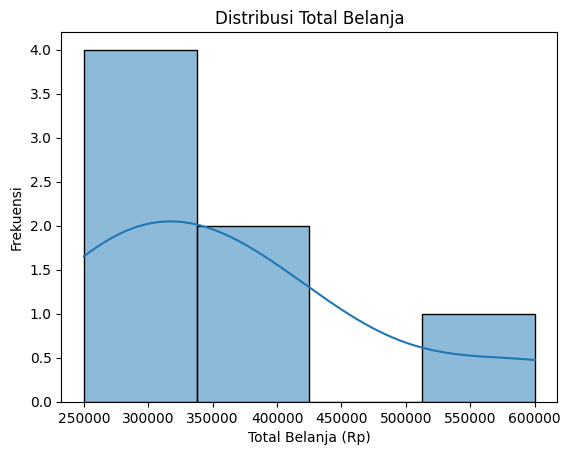

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Distribusi Total Belanja
sns.histplot(df['Total_Belanja'], kde=True)
plt.title("Distribusi Total Belanja")
plt.xlabel("Total Belanja (Rp)")
plt.ylabel("Frekuensi")
plt.show()


Distribusi total belanja bukanlah distribusi normal, melainkan right-skewed distribution. Right-skewed (juga disebut positively skewed) artinya sebagian besar data berkumpul di sisi kiri grafik (nilai kecil), dan ada beberapa data bernilai besar yang "menarik" ekornya ke kanan.

Salah satu cirinya adalah Mean > Median > Mode. Dan di kasus data ini,
- Median total belanja: 320.000
- Mean total belanja: 363.571
- Maksimum: 600.000 (jauh dari mayoritas data)

Nah, ini tanda bahwa ada sebagian kecil pelanggan yang belanjanya jauh lebih tinggi dari yang lain, jadi bentuk distribusinya right-skewed.

# Z-Score

In [ ]:
# untuk menghitung z-score perlu mean dan std-nya. Kita masukkan ke dalam variabel
mean_belanja = df['Total_Belanja'].mean()
std_belanja = df['Total_Belanja'].std()


# menghitung z-score
# total belanja sebagai x

df['Z_Score_Belanja'] = (df['Total_Belanja'] - mean_belanja) / std_belanja

In [ ]:
df

,Nama,Usia,Total_Belanja,Gender,Z_Score_Belanja
0,Ani,23,250000,F,-0.952871
1,Budi,35,400000,M,0.305638
2,Citra,31,300000,F,-0.533368
3,Dedi,28,275000,M,-0.743119
4,Eka,40,600000,F,1.983649
5,Fahmi,29,320000,M,-0.365567
6,Gina,35,400000,F,0.305638


Interpretasi:
- Ani (-0.95): Belanja Ani sekitar 1 standar deviasi di bawah rata-rata. Artinya, belanja dia lebih kecil dibanding kebanyakan orang di data ini.

- Eka (+1.98): Belanja Eka sekitar 2 standar deviasi di atas rata-rata, bisa dianggap belanjanya sangat tinggi dibanding yang lain.

- Z-score dekat nol (misalnya 0.1 atau -0.2) berarti belanja mereka sangat dekat dengan rata-rata.